## MSE Tendency Calculation
In a full GCM simulation, the surface pressure varies with time, so order of derivative and integral is important in the MSE tendency equation. Advection just treated as a residual, so hard to do a sanity check that way. But here show calculation is pretty different if do integral before derivative.

In [1]:
import sys
import os

# REMOTE - So can access functions in isca_tools which is in home/Isca directory
# sys.path.append(os.path.join(os.environ['HOME'], 'Isca'))
# LOCAL - So can access functions in isca_tools which is in StAndrews/Isca
sys.path.append(os.environ['PWD'])
from isca_tools.utils.constants import kappa, L_v, c_p, c_p_ocean, rho_ocean, Stefan_Boltzmann, R, R_v, g, radius_earth

import numpy as np
import matplotlib.pyplot as plt

from jobs.thesis_season.publish_figs.load import load_ds, var_keep, lat_target, spline_deriv_periodic_xr, \
    day_seconds, process_ds, get_fourier_fit_xr

# Use custom matplotlib style for publishing
plt.style.use('/Users/joshduffield/Documents/StAndrews/Isca/jobs/tau_sweep/aquaplanet/publish_figures/publish.mplstyle')
ax_linewidth = plt.rcParams['axes.linewidth']

In [2]:
exp_dir: str = 'thesis_season/publish_exp/advect'
exp_name = 'k=1'
ds_base = load_ds(exp_name, exp_dir, first_month_file=25, var_keep=var_keep, verbose=True, lat_target=lat_target)

Computing column temp, sphum, and rh: 100%|██████████| 3/3 [00:17<00:00,  5.95s/it]


In [3]:
ds = process_ds(ds_base)

### Sanity Check
Below I do a sanity check that the MSE tendency saved in the ds is the same as that calculated from column temperature and specific humidity.

In [4]:
def get_error(var, var_approx, time=ds.time, annual_harmonic=False):
    var_fourier, var_amp, _ = get_fourier_fit_xr(time, var, n_harmonics=1, pad_coefs_phase=True, pos_amp=True)
    var_amp = var_amp.sel(harmonic=1)
    if annual_harmonic:
        var_approx_fourier = get_fourier_fit_xr(time, var_approx, n_harmonics=1, pad_coefs_phase=True, pos_amp=True)[0]
        return np.abs(var_fourier - var_approx_fourier).mean(dim='time') / var_amp * 100
    else:
        # Get error relative to annual harmonic amplitude
        return np.abs(var-var_approx).mean(dim='time') / var_amp * 100

def get_mse_tend_calc(ds, mean_pressure: bool=False):
    # p_integ_calc_av = ds.p_integ_calc.mean(dim='time')
    temp_col_tend = spline_deriv_periodic_xr(ds.time * day_seconds, ds.temp_col)
    sphum_col_tend = spline_deriv_periodic_xr(ds.time * day_seconds, ds.sphum_col)
    c_atm_dry = c_p * ds.p_integ_calc / g
    if mean_pressure:
        c_atm_dry = c_atm_dry.mean(dim='time')
    mse_tend_dry = c_atm_dry * temp_col_tend

    mse_tend_moist = c_atm_dry * L_v / c_p * sphum_col_tend
    mse_tend = mse_tend_dry + mse_tend_moist
    return mse_tend, mse_tend_dry, mse_tend_moist

Error = 0.001%
Error (const p) = 0.680%


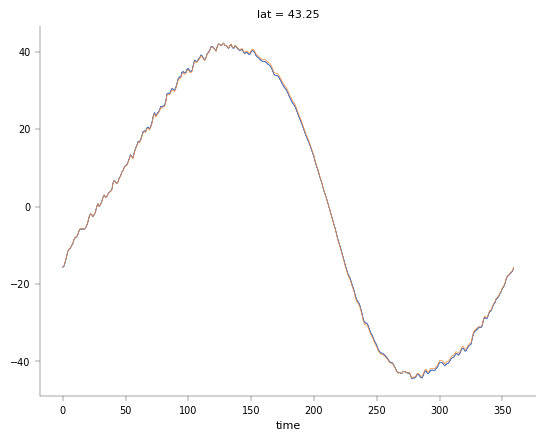

In [5]:
mse_type = 'full'

if mse_type == 'full':
    var_sim = ds.mse_tend_atmos
    ind = 0
elif mse_type == 'moist':
    var_sim = L_v*ds.sphum_col_tend
    ind = 2
elif mse_type == 'dry':
    var_sim = ds.mse_tend_atmos - L_v*ds.sphum_col_tend
    ind = 1
var = get_mse_tend_calc(ds)[ind]
var_av = get_mse_tend_calc(ds, True)[ind]

var_sim.plot(color='k')
var.plot()
var_av.plot()
print(f"Error = {get_error(var_sim, var).values[0]:.3f}%")
print(f"Error (const p) = {get_error(var_sim, var_av).values[0]:.3f}%")

### Leibnitz Correction to old method
Below I show that if I do the derivative after the integral, as is done previously then you need a leibnitz correction. Basically this is just to show old method is wrong.
Even with Leibnitz correction, does not quite match. Not sure why, but not important as don't do this any more.

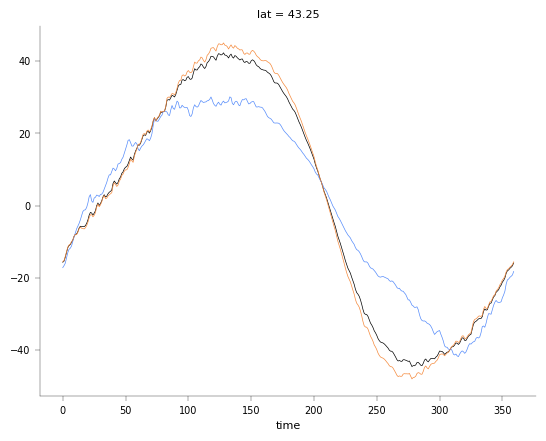

In [6]:
mse_tend_old = spline_deriv_periodic_xr(ds.time * day_seconds,
                                        (c_p * ds.temp_col + L_v * ds.sphum_col) * ds.p_integ_calc / g)

ds.mse_tend_atmos.plot(color='k')
mse_tend_old.plot()

p_atm_tend = spline_deriv_periodic_xr(ds.time * day_seconds, (ds.p_surf*ds.sigma_atm))
mse_leibnitz = -p_atm_tend * (c_p * ds.temp_atm + L_v * ds.q_atm) / g
(mse_leibnitz+mse_tend_old).plot()